# 데이터 + HCX 으로 generator만들기

C:\dev\t4core-stat-agent\population_files\data\generator.ipynb 
파일은 다음과 같다.
C:\dev\t4core-stat-agent\population_files\data\population_table_catalog.jsonl 파일을 dataframe으로 가져온다.
사용자가 LLM에 질문 쿼리를 넣으면 LLM은 질문에 대한 정보를 담은 행을 json 파일에서 읽고 해당 링크에 들어가 구체적인 데이터를 읽는다.
데이터를 기반으로 사용자의 질문에 답을 생성한다.

## 실험 설계: RAG 유무 / 검색 방식별 비교

| 방식 | 표 후보를 LLM에 주는 방법 |
|---|---|
| `no_rag` | 카탈로그 **전체(2,364개 표)** 를 그대로 프롬프트에 넣고 LLM이 표 선택 |
| `tfidf` | TF-IDF(kiwi 형태소) 상위 K개 → LLM이 표 선택 |
| `bm25` | BM25(kiwi 형태소) 상위 K개 → LLM이 표 선택 |
| `bm25+dense` | BM25 + 임베딩(dense) 검색을 RRF로 결합한 상위 K개 → LLM이 표 선택 |

**공정성**: 표 선택 이후 단계(메타 조회 → 조회조건 생성 → KOSIS API 호출 → 답변 생성)는 모든 방식이 같은 함수를 쓰고,
`(질문, 선택된 표)` 단위로 캐시합니다. 따라서 방식 간 차이는 **어떤 표를 골랐는가**에서만 생깁니다.

**평가 순서**
1. 검색 단독 평가 (LLM 호출 없음): Recall@1/5/20, MRR
2. End-to-end 평가: 표 선택 정확도(Hit@1, Hit@5), 선택 단계 토큰·지연, 최종 답변
3. (선택) LLM-judge로 답변 품질 점수

## 0. 설정

In [12]:
import os, sys, re, json, time, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
from dotenv import load_dotenv
from openai import OpenAI, BadRequestError

# 노트북 위치(population_files/data) 또는 프로젝트 루트 어디서 실행해도 동작
DATA_DIR = next(p for p in [Path.cwd(), Path.cwd() / "population_files" / "data"]
                if (p / "population_table_catalog.jsonl").exists())
ROOT = DATA_DIR.parents[1]
CATALOG = DATA_DIR / "population_table_catalog.jsonl"
CACHE = DATA_DIR / "cache"
RESULTS = DATA_DIR / "results"
CACHE.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

load_dotenv(ROOT / ".env")
sys.path.insert(0, str(ROOT))
import kosis_rag_builder as kosis              # KOSIS 호출(call/get_meta/parse_itm/parse_prd) 재사용
kosis.API_KEY = os.getenv("KOSIS_API_KEY")      # 모듈은 cwd/.env 를 읽으므로 루트 .env 값으로 덮어씀

MODEL = os.getenv("HCX_MODEL", "HCX-005")
EMBED_MODEL = os.getenv("HCX_EMBED_MODEL", "bge-m3")
assert kosis.API_KEY, ".env 에 KOSIS_API_KEY 필요"
assert os.getenv("HCX_API_KEY"), ".env 에 HCX_API_KEY / HCX_BASE_URL / HCX_MODEL 필요 (.env.example 참고)"
client = OpenAI(api_key=os.getenv("HCX_API_KEY"), base_url=os.getenv("HCX_BASE_URL"))

TOP_K = 20          # RAG 방식에서 LLM에 넘길 후보 수
print(DATA_DIR, MODEL, EMBED_MODEL)

c:\dev\t4core-stat-agent\population_files\data HCX-005 bge-m3


## 1. 카탈로그 로드
검색 대상 문서(`doc`) = 조사명 + 표 이름 + 분류 경로 + 수록기간

In [13]:
df = pd.read_json(CATALOG, lines=True, dtype={"org_id": str, "tbl_id": str})
df["path"] = df["paths"].map(lambda p: p[0]["path"])
df["url"] = df["paths"].map(lambda p: p[0]["kosis_table_url"])
df["doc"] = (df["survey_name"] + " | " + df["table_name"] + " | "
             + df["path"].str.replace("주제별통계 > 인구 > ", "", regex=False) + " | " + df["period"])
df = df.reset_index(drop=True)
BY_ID = df.set_index("tbl_id")
VALID_IDS = set(df["tbl_id"])

print(len(df), "tables")
df[["tbl_id", "survey_name", "table_name", "period"]].head()

2364 tables


,tbl_id,survey_name,table_name,period
0,DT_1IN1502,인구총조사,"인구, 가구 및 주택 – 읍면동(연도 끝자리 0, 5), 시군구(그 외 연도)",년 (2015 ~ 2025)
1,DT_1IN1503,인구총조사,연령 및 성별 인구 – 읍면동,년 (2015 ~ 2025)
2,DT_1IN2030,인구총조사,"주요 인구지표(부양비, 노령화지수, 중위연령 등) - 시군구",년 (2015 ~ 2025)
3,DT_1IN1507,인구총조사,"성, 연령 및 가구주와의 관계별 인구 - 시군구",년 (2015 ~ 2025)
4,DT_1IN1509,인구총조사,"성, 연령 및 세대구성별 인구 - 시군구",년 (2015 ~ 2025)


## 2. 평가용 질문셋
`gold` = 질문에 답할 수 있는 정답 표(복수 허용). 표현을 바꾼 질문("이사 간 사람" ↔ "이동자수")을 섞어
lexical 검색(TF-IDF/BM25)과 dense 검색의 차이가 드러나게 했습니다. 필요에 따라 추가하세요.

In [14]:
EVAL = [
    {"q": "2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?",            "gold": ["DT_1B81A23", "DT_1B81A17"]},
    {"q": "2025년 전국 노령화지수와 중위연령 알려줘",                         "gold": ["DT_1IN2030"]},
    {"q": "2050년 우리나라 총인구는 얼마로 전망돼?",                          "gold": ["DT_1BPA001", "DT_1BPA003", "DT_1BPA401"]},
    {"q": "2024년 시도별 외국인주민 수는?",                                    "gold": ["TX_11025_A000_A"]},
    {"q": "2025년에 서울에서 경기도로 이사 간 사람은 몇 명이야?",               "gold": ["DT_1B26003_A01", "DT_1B26003"]},
    {"q": "2024년 출생아 수와 사망자 수는?",                                   "gold": ["DT_1B8000G", "DT_1B8000F", "INH_1B8000F_01"]},
    {"q": "아이를 적게 낳는다는데 2024년 출산율 수준은 어때?",                  "gold": ["INH_1B8000F_01", "DT_1B8000G", "DT_1B81A21"]},
    {"q": "2070년 기대수명은 몇 살로 예상돼?",                                  "gold": ["DT_1BPA201"]},
    {"q": "서울 강남구 주민등록 인구 남녀 수",                                  "gold": ["DT_1B040A3"]},
    {"q": "2024년 국적별 체류자격별 외국인 입국자 수",                          "gold": ["DT_091_111_2009_S006", "DT_1B28023"]},
    {"q": "고령친화 용품 수출액은 얼마나 돼?",                                  "gold": ["DT_358005_008"]},
    {"q": "2023년 누적 혼인 비율은?",                                           "gold": ["DT_101094A001"]},
    {"q": "2025년 시군구별 성별 연령별 혼자 사는 가구 수",                      "gold": ["DT_1PL1502"]},
]
missing = {g for e in EVAL for g in e["gold"]} - VALID_IDS
assert not missing, f"카탈로그에 없는 gold: {missing}"
print(len(EVAL), "questions")

13 questions


## 3. 공통 도구: LLM 호출 / 형태소 토큰

In [15]:
from openai import RateLimitError

# CLOVA Studio chat 한도 (응답 헤더 실측): 분당 60회, 분당 60,000 토큰 (reset 60s)
TPM_LIMIT = 60_000


def _reset_sec(e, default=20.0):
    """429 응답 헤더(x-ratelimit-reset-*, retry-after)에서 대기 시간(초) 추출"""
    h = getattr(getattr(e, "response", None), "headers", {}) or {}
    secs = []
    for k in ("retry-after", "x-ratelimit-reset-tokens", "x-ratelimit-reset-requests"):
        m = re.match(r"([\d.]+)", str(h.get(k, "")))
        if m:
            secs.append(float(m.group(1)))
    return max(secs) if secs else default


def chat(messages, max_tokens=1024, temperature=0.0, retries=6):
    """HCX 호출 → (응답 텍스트, 사용량 dict). 429면 한도 리셋까지 기다렸다 재시도"""
    t0 = time.perf_counter()
    for attempt in range(retries):
        try:
            r = client.chat.completions.create(model=MODEL, messages=messages,
                                               max_tokens=max_tokens, temperature=temperature)
            break
        except RateLimitError as e:
            if attempt == retries - 1:
                raise
            wait = _reset_sec(e) + 1
            print(f"  429 rate limit → {wait:.0f}s 대기 후 재시도 ({attempt + 1}/{retries - 1})")
            time.sleep(wait)
    u = r.usage
    return r.choices[0].message.content, {
        "prompt_tokens": getattr(u, "prompt_tokens", 0) or 0,
        "completion_tokens": getattr(u, "completion_tokens", 0) or 0,
        "sec": time.perf_counter() - t0,
    }


def parse_json(text):
    """응답에서 첫 JSON 객체만 추출 (코드블록·앞뒤 설명 허용)"""
    m = re.search(r"\{.*\}", text, re.S)
    if not m:
        raise ValueError(f"JSON 없음: {text[:200]}")
    return json.loads(m.group(0))


def sum_usage(us):
    return {k: sum(u[k] for u in us) for k in ("prompt_tokens", "completion_tokens", "sec")}


from kiwipiepy import Kiwi
kiwi = Kiwi()
KEEP_TAGS = ("NN", "VV", "VA", "XR", "SL", "SN", "SH")   # 명사·동사·형용사 어근·외국어·숫자·한자


def tokenize(text):
    return [t.form for t in kiwi.tokenize(text) if t.tag.startswith(KEEP_TAGS)]


DOC_TOKENS = [tokenize(d) for d in df["doc"]]
print(df["doc"][0], "\n→", DOC_TOKENS[0])

인구총조사 | 인구, 가구 및 주택 – 읍면동(연도 끝자리 0, 5), 시군구(그 외 연도) | 인구총조사 > 인구부문 > 총조사인구(2015년 이후) > 전수부문 (등록센서스, 2015년 이후) > 전수기본표 > 인구, 가구 및 주택 – 읍면동(연도 끝자리 0, 5), 시군구(그 외 연도) | 년 (2015 ~ 2025) 
→ ['인구', '총조사', '인구', '가구', '주택', '읍면동', '연도', '끝자리', '0', '5', '시군구', '외', '연도', '인구', '총조사', '인구', '부문', '총조사인구', '2015', '년', '이후', '전수', '부문', '등록', '센서스', '2015', '년', '이후', '전수기본표', '인구', '가구', '주택', '읍면동', '연도', '끝자리', '0', '5', '시군구', '외', '연도', '년', '2015', '2025']


## 4. Retriever 정의
모두 `retrieve(question, k) -> df 행 인덱스 리스트(점수 내림차순)` 형태로 맞춥니다.

### 4-1. TF-IDF

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(analyzer=lambda toks: toks, sublinear_tf=True)   # 이미 토큰화된 리스트 입력
X_TFIDF = tfidf.fit_transform(DOC_TOKENS)                                # L2 정규화 → 내적 = 코사인


def retrieve_tfidf(q, k=TOP_K):
    s = (X_TFIDF @ tfidf.transform([tokenize(q)]).T).toarray().ravel()
    return np.argsort(-s)[:k].tolist()

### 4-2. BM25

In [17]:
from rank_bm25 import BM25Okapi

bm25 = BM25Okapi(DOC_TOKENS)


def retrieve_bm25(q, k=TOP_K):
    return np.argsort(-bm25.get_scores(tokenize(q)))[:k].tolist()

### 4-3. Dense (임베딩) + BM25 하이브리드
- 임베딩: CLOVA Studio OpenAI 호환 `/embeddings` (`HCX_EMBED_MODEL`, 기본 `bge-m3`). 문서 임베딩은 `cache/`에 저장해 1회만 계산
- 결합: Reciprocal Rank Fusion (RRF, k=60). 점수 스케일이 다른 두 검색을 순위 기반으로 합침

In [18]:
from openai import RateLimitError
from tqdm.auto import tqdm

# CLOVA Studio OpenAI 호환 /embeddings 제약 (실측):
#  - input 은 문자열 1개만 (리스트 → 400 "convert error")
#  - encoding_format="float" 필수 (openai SDK 기본값 base64 → 400 "encoding_format")
#  - 분당 60회 (응답 헤더 x-ratelimit-limit-requests=60, reset 15s)
EMBED_RPM = 60
_last_call = [0.0]


def _embed_one(text, retries=6):
    for attempt in range(retries):
        wait = _last_call[0] + 60 / EMBED_RPM + 0.05 - time.monotonic()
        if wait > 0:
            time.sleep(wait)
        _last_call[0] = time.monotonic()
        try:
            r = client.embeddings.create(model=EMBED_MODEL, input=text, encoding_format="float")
            return r.data[0].embedding
        except BadRequestError:
            raise                                  # 요청 형식 오류는 재시도해도 같은 결과
        except RateLimitError:
            time.sleep(15)                         # x-ratelimit-reset-requests
        except Exception as e:                     # 네트워크 등 → 대기 후 재시도
            if attempt == retries - 1:
                raise
            print("embed retry:", e)
            time.sleep(5 * (attempt + 1))
    raise RuntimeError("embed: 재시도 초과")


def embed(texts):
    v = np.asarray([_embed_one(t) for t in texts], dtype=np.float32)
    return v / np.linalg.norm(v, axis=1, keepdims=True)


# 문서 임베딩: 2,364개 × 분당 60회 ≈ 40분. 100개마다 중간 저장 → 끊겨도 다시 실행하면 이어서 진행
_key = hashlib.md5(("\n".join(df["doc"]) + EMBED_MODEL).encode()).hexdigest()[:10]
EMB_PATH = CACHE / f"doc_emb_{_key}.npy"
PART_PATH = CACHE / f"doc_emb_{_key}.partial.npy"
if EMB_PATH.exists():
    DOC_EMB = np.load(EMB_PATH)
else:
    docs = df["doc"].tolist()
    done = list(np.load(PART_PATH)) if PART_PATH.exists() else []
    pbar = tqdm(total=len(docs), initial=len(done), desc="embed docs")
    for i in range(len(done), len(docs)):
        done.append(embed([docs[i]])[0])
        pbar.update(1)
        if len(done) % 100 == 0:
            np.save(PART_PATH, np.asarray(done, dtype=np.float32))
    pbar.close()
    DOC_EMB = np.asarray(done, dtype=np.float32)
    np.save(EMB_PATH, DOC_EMB)
    PART_PATH.unlink(missing_ok=True)
print("DOC_EMB", DOC_EMB.shape)

_q_emb = {}


def retrieve_dense(q, k=TOP_K):
    if q not in _q_emb:
        _q_emb[q] = embed([q])[0]
    return np.argsort(-(DOC_EMB @ _q_emb[q]))[:k].tolist()


def rrf(rankings, k=60):
    score = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking):
            score[i] = score.get(i, 0.0) + 1.0 / (k + rank + 1)
    return sorted(score, key=score.get, reverse=True)


def retrieve_hybrid(q, k=TOP_K, pool=100):
    return rrf([retrieve_bm25(q, pool), retrieve_dense(q, pool)])[:k]


RETRIEVERS = {"tfidf": retrieve_tfidf, "bm25": retrieve_bm25, "bm25+dense": retrieve_hybrid}

DOC_EMB (2364, 1024)


## 5. 검색 단독 평가 (LLM 호출 없음)
`no_rag`는 검색기가 없으므로 여기서는 제외하고 6단계에서 LLM 선택 결과로 비교합니다.
`dense`(임베딩 단독)는 하이브리드 효과를 보기 위한 참고용입니다.

In [19]:
def gold_rank(idx_list, gold):
    """후보 리스트에서 첫 정답의 순위(1부터). 없으면 NaN"""
    for r, t in enumerate(df.loc[idx_list, "tbl_id"], 1):
        if t in gold:
            return r
    return np.nan


rows = []
for name, fn in {**RETRIEVERS, "dense(참고)": retrieve_dense}.items():
    for e in EVAL:
        rows.append({"method": name, "q": e["q"], "rank": gold_rank(fn(e["q"], 100), set(e["gold"]))})
ret_df = pd.DataFrame(rows)

ret_summary = ret_df.groupby("method", sort=False)["rank"].agg(
    **{"R@1": lambda s: (s <= 1).mean(),
       "R@5": lambda s: (s <= 5).mean(),
       f"R@{TOP_K}": lambda s: (s <= TOP_K).mean(),
       "MRR": lambda s: (1 / s).fillna(0).mean()}).round(3)
display(ret_summary)
display(ret_df.pivot(index="q", columns="method", values="rank"))   # 질문별 정답 순위

,R@1,R@5,R@20,MRR
method,,,,
tfidf,0.538,0.538,0.615,0.553
bm25,0.538,0.615,0.692,0.570
bm25+dense,0.538,0.692,0.846,0.632
dense(참고),0.538,0.769,0.846,0.641


method,bm25,bm25+dense,dense(참고),tfidf
q,,,,
2023년 누적 혼인 비율은?,1.0,1.0,1.0,1.0
2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?,1.0,1.0,2.0,1.0
2024년 국적별 체류자격별 외국인 입국자 수,1.0,1.0,1.0,1.0
2024년 시도별 외국인주민 수는?,1.0,1.0,1.0,1.0
2024년 출생아 수와 사망자 수는?,20.0,2.0,21.0,34.0
2025년 시군구별 성별 연령별 혼자 사는 가구 수,NaN,32.0,5.0,NaN
2025년 전국 노령화지수와 중위연령 알려줘,1.0,1.0,1.0,1.0
2025년에 서울에서 경기도로 이사 간 사람은 몇 명이야?,NaN,NaN,54.0,NaN
2050년 우리나라 총인구는 얼마로 전망돼?,NaN,8.0,2.0,NaN


## 6. 표 선택 (LLM)
- RAG 방식: 검색 상위 `TOP_K`개만 목록으로 제공
- `no_rag`: 전체 카탈로그를 한 번에 제공. 컨텍스트 한도를 넘으면 `NO_RAG_CHUNK`개씩 나눠 1차 선택 후 최종 선택(map-reduce)으로 자동 전환하고, 그 사실을 결과에 기록

In [20]:
SELECT_SYS = """너는 KOSIS 통계표 검색 도우미다. 사용자 질문에 답할 수 있는 통계표를 [통계표 목록]에서만 고른다.
반드시 JSON 한 개만 출력한다: {"tbl_ids": ["가장 적합한 tbl_id", "2순위", ... 최대 5개], "reason": "한 문장"}
목록에 없는 tbl_id를 만들지 마라. 적합한 표가 없으면 tbl_ids를 빈 리스트로 둔다."""

NO_RAG_CHUNK = 600


def catalog_text(idx):
    return "\n".join(f"{r.tbl_id} | {r.survey_name} | {r.table_name} | {r.period}"
                     for r in df.loc[idx].itertuples())


def select_table(q, idx):
    text, u = chat([{"role": "system", "content": SELECT_SYS},
                    {"role": "user", "content": f"[통계표 목록]\n{catalog_text(idx)}\n\n[질문]\n{q}"}],
                   max_tokens=300)
    try:
        ids = [t for t in parse_json(text).get("tbl_ids", []) if t in VALID_IDS]
    except ValueError:
        ids = []
    return ids, [u]


TOKENS_PER_ROW = 43          # 실측: 카탈로그 100행 ≈ 4,300 토큰 → 전체 2,364행 ≈ 10만 토큰


def select_norag(q):
    # 전체 목록이 분당 토큰 한도(TPM_LIMIT)를 넘으면 한 번에 보내는 건 재시도해도 항상 429 → 바로 분할
    if len(df) * TOKENS_PER_ROW < TPM_LIMIT * 0.9:
        try:
            ids, us = select_table(q, list(df.index))
            return ids, us, "full"
        except (BadRequestError, RateLimitError) as e:   # 컨텍스트 초과·토큰 한도 등
            print("  no_rag 전체 입력 실패 → 분할 선택:", str(e)[:120])
    else:
        print(f"  no_rag 전체 ≈{len(df) * TOKENS_PER_ROW:,} 토큰 > 분당 한도 {TPM_LIMIT:,} → 분할 선택")
    us, pool = [], []
    for s in range(0, len(df), NO_RAG_CHUNK):
        ids, u = select_table(q, list(range(s, min(s + NO_RAG_CHUNK, len(df)))))
        us += u
        pool += ids
    pool_idx = df.index[df["tbl_id"].isin(pool)].tolist()
    ids, u = select_table(q, pool_idx) if pool_idx else ([], [])
    return ids, us + u, "chunked"


print(f"no_rag 목록 길이: {len(catalog_text(list(df.index))):,} chars")

no_rag 목록 길이: 164,338 chars


## 7. 데이터 조회 + 답변 생성 (모든 방식 공통)
1. 메타 조회(`getMeta` ITM/PRD) — 기존 `kosis_data/meta/` 캐시 재사용
2. LLM이 메타를 보고 조회 조건(시점·분류코드·항목) JSON 생성
3. `statisticsParameterData` 호출 → DataFrame
4. 데이터를 CSV 텍스트로 축약해 LLM이 답변 생성

`(질문, tbl_id)`가 같으면 결과를 재사용 → 방식 간 차이는 표 선택에서만 발생

In [21]:
META_DIR = ROOT / "kosis_data" / "meta"
META_DIR.mkdir(parents=True, exist_ok=True)


def load_meta(org, tbl):
    p = META_DIR / f"{org}_{tbl}.json"                # kosis_rag_builder.meta_path 와 같은 규칙
    if p.exists():
        raw = json.loads(p.read_text(encoding="utf-8"))
    else:
        raw = {t: kosis.get_meta(org, tbl, t) for t in ("ITM", "PRD")}
        p.write_text(json.dumps(raw, ensure_ascii=False), encoding="utf-8")
    levels, items = kosis.parse_itm(raw["ITM"])
    return {"levels": levels, "items": items, "prd": kosis.parse_prd(raw["PRD"])}


def meta_text(meta, max_codes=300):
    lines = ["[시점] " + ", ".join(f"{se}: {v[0]}~{v[-1]}" for se, v in meta["prd"].items())]
    lines.append("[항목 itmId] " + ", ".join(f"{i['id']}={i['nm']}({i['unit']})" for i in meta["items"]))
    for n, lv in enumerate(meta["levels"], 1):
        codes = lv["codes"][:max_codes]
        more = f" …외 {len(lv['codes']) - max_codes}개" if len(lv["codes"]) > max_codes else ""
        lines.append(f"[분류{n} {lv['obj_nm']}] " + ", ".join(f"{c['id']}={c['nm']}" for c in codes) + more)
    if meta["levels"]:
        order = ", ".join(f"{n}={lv['obj_nm']}" for n, lv in enumerate(meta["levels"], 1))
        lines.append(f"[objL 순서] {order} → objL 은 리스트 {len(meta['levels'])}개 (빠짐없이)")
    return "\n".join(lines)


def fix_plan(plan, meta, q):
    """질문에 연도가 있고 그 연도가 표에 있으면 시점을 질문 기준으로 맞춤 (LLM이 최근 연도를 임의로 고르는 문제 방지)"""
    years = sorted(set(re.findall(r"(?<!\d)((?:19|20)\d{2})(?=\s*년)", q)))
    prd = meta["prd"].get(plan.get("prdSe"), [])
    ok = [y for y in years if any(p.startswith(y) for p in prd)]
    if ok and not (str(plan.get("start", ""))[:4] in ok and str(plan.get("end", ""))[:4] in ok):
        first = [p for p in prd if p.startswith(ok[0])]
        last = [p for p in prd if p.startswith(ok[-1])]
        plan = {**plan, "start": first[0], "end": last[-1]}
    return plan


PLAN_SYS = """너는 KOSIS OpenAPI 조회 조건을 만드는 도우미다. 질문에 답하는 데 필요한 최소 범위만 고른다.
반드시 JSON 한 개만 출력한다:
{"prdSe": "Y", "start": "2023", "end": "2023", "itmId": ["항목코드", ...], "objL": [["분류1 코드", ...], ["분류2 코드", ...], ...]}
- objL 은 분류 개수만큼, 분류 순서대로 쓴다. 빠뜨리는 분류가 없어야 한다.
- 질문과 관계없는 분류는 합계·전체에 해당하는 코드 하나만 쓴다 (예: 연령별 → 합계 코드).
- 질문에 필요한 코드만 나열한다. "ALL"은 그 분류의 모든 코드가 꼭 필요할 때만 단독으로 쓰고, 다른 코드와 섞지 않는다.
- 코드·시점은 반드시 [메타]에 있는 값만 쓴다. 질문에 나온 시점을 그대로 쓰고, 시점이 없으면 가장 최근 시점 하나."""


def make_plan(q, row, meta):
    text, u = chat([{"role": "system", "content": PLAN_SYS},
                    {"role": "user", "content": f"[통계표] {row.table_name}\n[메타]\n{meta_text(meta)}\n\n[질문]\n{q}"}],
                   max_tokens=500)
    return fix_plan(parse_json(text), meta, q), u


def join_codes(codes, valid, default):
    """LLM이 고른 코드 정리 → KOSIS 파라미터 문자열.
    메타에 없는 코드는 버리고, 'ALL'이 다른 코드와 섞여 있으면 코드만 사용.
    아무것도 안 남으면 default(분류는 첫 코드 = 보통 합계·전국) → 셀 수 초과(4만 셀) 방지"""
    codes = [str(c) for c in (codes or [])]
    valid = set(valid)
    picked = [c for c in codes if c in valid]
    if picked:
        return "+".join(picked) + "+"
    return "ALL" if "ALL" in codes else default


def fetch_data(row, meta, plan):
    key = hashlib.md5(json.dumps([row.name, plan], sort_keys=True, ensure_ascii=False).encode()).hexdigest()[:12]
    p = CACHE / f"data_{key}.json"
    if p.exists():
        return pd.DataFrame(json.loads(p.read_text(encoding="utf-8")))
    objl = plan.get("objL", [])
    params = {"method": "getList", "orgId": row.org_id, "tblId": row.name,
              "itmId": join_codes(plan.get("itmId"), [i["id"] for i in meta["items"]], default="ALL"),
              "prdSe": plan["prdSe"], "startPrdDe": plan["start"], "endPrdDe": plan["end"]}
    for k, lv in enumerate(meta["levels"][:8]):
        ids = [c["id"] for c in lv["codes"]]
        params[f"objL{k + 1}"] = join_codes(objl[k] if k < len(objl) else None, ids, default=ids[0])
    data = kosis.call(kosis.URL_DATA, params)
    p.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    return pd.DataFrame(data)


DATA_COLS = ["PRD_DE", "C1_NM", "C2_NM", "C3_NM", "C4_NM", "ITM_NM", "DT", "UNIT_NM"]


def data_text(d, max_rows=200):
    d = d[[c for c in DATA_COLS if c in d.columns]]
    s = d.head(max_rows).to_csv(index=False)
    return s + (f"... (총 {len(d)}행 중 {max_rows}행만 표시)\n" if len(d) > max_rows else "")


ANSWER_SYS = """너는 한국 인구통계 분석가다. 제공된 [데이터]만 근거로 질문에 답한다.
- 수치는 단위와 시점을 함께 쓴다.
- 데이터에 없는 내용은 추정하지 말고 '제공된 데이터에 없음'이라고 말한다.
- 마지막 줄에 '출처: 통계표명(tbl_id)'를 쓴다."""

_downstream = {}   # (q, tbl_id) → 결과 캐시


def answer_with_table(q, tbl_id):
    if (q, tbl_id) in _downstream:
        return _downstream[(q, tbl_id)]
    row = BY_ID.loc[tbl_id]
    us, out = [], {"plan": None, "n_rows": 0, "answer": None, "error": None}
    try:
        meta = load_meta(row.org_id, tbl_id)
        plan, u = make_plan(q, row, meta); us.append(u)
        data = fetch_data(row, meta, plan)
        out.update(plan=plan, n_rows=len(data))
        if data.empty:
            raise ValueError("조회 결과 없음")
        text, u = chat([{"role": "system", "content": ANSWER_SYS},
                        {"role": "user", "content": f"[통계표] {row.table_name} ({tbl_id})\n"
                                                    f"[출처] {row.source_text} / {row.url}\n"
                                                    f"[데이터]\n{data_text(data)}\n\n[질문]\n{q}"}])
        us.append(u)
        out["answer"] = text
    except Exception as e:
        out["error"] = f"{type(e).__name__}: {e}"
    out["downstream_usage"] = sum_usage(us) if us else sum_usage([{"prompt_tokens": 0, "completion_tokens": 0, "sec": 0}])
    _downstream[(q, tbl_id)] = out
    return out

## 7-1. 단일 표 모드 (표 선택 없이 지정한 표 하나만 사용)
카탈로그 전체를 LLM에 넘기지 않고, `FIXED_TBL` 표 하나의 메타만 LLM에 줘서 조회 조건 생성 → 데이터 조회 → 답변.

코드가 많은 분류(예: 읍면동 4,159개)는 그대로 넣으면 앞 300개만 잘려 보이므로 `narrow_meta`로 줄입니다:
- 상위 2단계(전국·시도·시군구)는 항상 포함
- 질문에 이름이 나온 코드 + 그 상위 + 바로 아래 하위
- 이름 앞에 상위 지역명을 붙여 동명 지역(예: 여러 `중구`)을 구분


In [22]:
FIXED_TBL = "DT_1IN1503"     # 연령 및 성별 인구 – 읍면동 (인구총조사, 2015~2025)


def _code_depth(by):
    """코드 id → 계층 깊이(최상위 1)"""
    depth = {}

    def f(cid):
        if cid not in depth:
            up = by[cid].get("up")
            depth[cid] = f(up) + 1 if up in by else 1
        return depth[cid]

    for cid in by:
        f(cid)
    return depth


def narrow_meta(meta, q, max_codes=300, keep_depth=2):
    """코드가 max_codes 넘는 분류만: 상위 keep_depth 단계 + 질문에 언급된 코드(상위·바로 아래 포함)"""
    levels = []
    for lv in meta["levels"]:
        codes = lv["codes"]
        if len(codes) <= max_codes:
            levels.append(lv)
            continue
        by = {c["id"]: c for c in codes}
        depth = _code_depth(by)
        hit = {c["id"] for c in codes if c["nm"] and len(c["nm"]) >= 2 and c["nm"] in q}
        keep = {cid for cid, d in depth.items() if d <= keep_depth} | hit
        for cid in hit:                                     # 상위 경로
            up = by[cid].get("up")
            while up in by:
                keep.add(up)
                up = by[up].get("up")
        keep |= {c["id"] for c in codes if c.get("up") in hit}   # 바로 아래

        def full_name(c):
            names, up = [c["nm"]], c.get("up")
            while up in by:
                names.insert(0, by[up]["nm"])
                up = by[up].get("up")
            return " ".join(names)

        levels.append({**lv, "codes": [{**c, "nm": full_name(c)} for c in codes if c["id"] in keep]})
    return {**meta, "levels": levels}


def code_hints(meta, q):
    """질문에 이름이 나온 코드(띄어쓰기 무시)를 분류별로 짚어 줌. 예: '65세 이상' → 65세이상.
    같은 분류에서 더 긴 이름에 포함되는 짧은 일치(65세 ⊂ 65세이상)는 뺌"""
    qs = re.sub(r"\s", "", q)
    lines = []
    for n, lv in enumerate(meta["levels"], 1):
        last = lambda c: re.sub(r"\s", "", c["nm"].split()[-1])   # narrow_meta가 붙인 상위 지역명 제외
        hits = [c for c in lv["codes"] if len(last(c)) >= 2 and last(c) in qs]
        hits = [c for c in hits if not any(last(c) != last(o) and last(c) in last(o) for o in hits)]
        if hits:
            lines.append(f"분류{n} {lv['obj_nm']}: " + ", ".join(f"{c['id']}={c['nm']}" for c in hits))
    return ("[질문과 일치하는 코드]\n" + "\n".join(lines)) if lines else ""


def answer_fixed(q, tbl_id=FIXED_TBL, verbose=True):
    """표 선택 없이 tbl_id 하나로 답변"""
    row = BY_ID.loc[tbl_id]
    us, out = [], {"tbl_id": tbl_id, "plan": None, "n_rows": 0, "answer": None, "error": None}
    try:
        meta = narrow_meta(load_meta(row.org_id, tbl_id), q)
        text, u = chat([{"role": "system", "content": PLAN_SYS},
                        {"role": "user", "content": f"[통계표] {row.table_name}\n[메타]\n{meta_text(meta, max_codes=2000)}\n{code_hints(meta, q)}\n\n[질문]\n{q}"}],
                       max_tokens=500)
        us.append(u)
        plan = fix_plan(parse_json(text), meta, q)
        data = fetch_data(row, meta, plan)
        out.update(plan=plan, n_rows=len(data))
        if data.empty:
            raise ValueError("조회 결과 없음")
        text, u = chat([{"role": "system", "content": ANSWER_SYS},
                        {"role": "user", "content": f"[통계표] {row.table_name} ({tbl_id})\n"
                                                    f"[출처] {row.source_text} / {row.url}\n"
                                                    f"[데이터]\n{data_text(data)}\n\n[질문]\n{q}"}])
        us.append(u)
        out["answer"] = text
    except Exception as e:
        out["error"] = f"{type(e).__name__}: {e}"
    out["usage"] = sum_usage(us) if us else None
    if verbose:
        print("plan:", out["plan"], "| rows:", out["n_rows"], "| usage:", out["usage"])
        print(out["answer"] or f"(오류) {out['error']}")
    return out


_ = answer_fixed("2025년 부산광역시 해운대구 동별 총인구 알려줘")


plan: {'prdSe': 'Y', 'start': '2025', 'end': '2025', 'itmId': ['T00'], 'objL': [['21', '21090'], ['000']]} | rows: 2 | usage: {'prompt_tokens': 5139, 'completion_tokens': 93, 'sec': 3.2059651000308804}
제공된 데이터에는 2025년도 부산광역시 해운대구의 동별 총인구에 대한 정보가 없습니다.

출처: DT_1IN1503


## 8. End-to-end 실행: 4가지 방식 × 질문셋

In [23]:
METHODS = ["no_rag", "tfidf", "bm25", "bm25+dense"]


def run(e, method):
    q, gold = e["q"], set(e["gold"])
    t0 = time.perf_counter()
    if method == "no_rag":
        ids, us, mode = select_norag(q)
        retrieval_hit = np.nan                       # 검색 단계 없음
    else:
        idx = RETRIEVERS[method](q, TOP_K)
        ids, us = select_table(q, idx)
        mode = f"top{TOP_K}"
        retrieval_hit = float(bool(gold & set(df.loc[idx, "tbl_id"])))
    sel = sum_usage(us)
    res = {"method": method, "q": q, "mode": mode,
           "selected": ids[0] if ids else None, "candidates": ids,
           f"retrieval_R@{TOP_K}": retrieval_hit,
           "hit@1": float(bool(ids) and ids[0] in gold),
           "hit@5": float(bool(gold & set(ids[:5]))),
           "sel_prompt_tokens": sel["prompt_tokens"], "sel_sec": round(sel["sec"], 2),
           "sel_llm_calls": len(us)}
    if ids:
        down = answer_with_table(q, ids[0])
        res.update(answer=down["answer"], error=down["error"], plan=down["plan"], n_rows=down["n_rows"],
                   total_prompt_tokens=sel["prompt_tokens"] + down["downstream_usage"]["prompt_tokens"])
    else:
        res.update(answer="적합한 통계표를 찾지 못했습니다.", error="no_table", plan=None, n_rows=0,
                   total_prompt_tokens=sel["prompt_tokens"])
    res["total_sec"] = round(time.perf_counter() - t0, 2)
    return res


results = []
for e in EVAL:
    for m in METHODS:
        print(f"[{m:10s}] {e['q']}")
        results.append(run(e, m))
res_df = pd.DataFrame(results)
res_df.to_csv(RESULTS / "compare_results.csv", index=False, encoding="utf-8-sig")
print("saved →", RESULTS / "compare_results.csv")

[no_rag    ] 2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?
  no_rag 전체 ≈101,652 토큰 > 분당 한도 60,000 → 분할 선택
  429 rate limit → 49s 대기 후 재시도 (1/5)
[tfidf     ] 2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?
[bm25      ] 2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?
[bm25+dense] 2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?
[no_rag    ] 2025년 전국 노령화지수와 중위연령 알려줘
  no_rag 전체 ≈101,652 토큰 > 분당 한도 60,000 → 분할 선택
  429 rate limit → 35s 대기 후 재시도 (1/5)
  429 rate limit → 52s 대기 후 재시도 (1/5)
[tfidf     ] 2025년 전국 노령화지수와 중위연령 알려줘
[bm25      ] 2025년 전국 노령화지수와 중위연령 알려줘
[bm25+dense] 2025년 전국 노령화지수와 중위연령 알려줘
[no_rag    ] 2050년 우리나라 총인구는 얼마로 전망돼?
  no_rag 전체 ≈101,652 토큰 > 분당 한도 60,000 → 분할 선택
  429 rate limit → 43s 대기 후 재시도 (1/5)
  429 rate limit → 57s 대기 후 재시도 (1/5)
[tfidf     ] 2050년 우리나라 총인구는 얼마로 전망돼?
[bm25      ] 2050년 우리나라 총인구는 얼마로 전망돼?
[bm25+dense] 2050년 우리나라 총인구는 얼마로 전망돼?
  429 rate limit → 40s 대기 후 재시도 (1/5)
[no_rag    ] 2024년 시도별 외국인주민 수는?
  no_rag 전체 ≈101,652 토큰 > 분당 한도 60,000 → 분할 선택
  429 rate limit → 48s 대기 후 재시도 (1/5)
[tfidf     ] 2024년 시도별 외국

## 9. 결과 비교

In [24]:
summary = res_df.groupby("method", sort=False).agg(
    표선택_Hit1=("hit@1", "mean"),
    표선택_Hit5=("hit@5", "mean"),
    검색_Recall=(f"retrieval_R@{TOP_K}", "mean"),
    선택단계_입력토큰=("sel_prompt_tokens", "mean"),
    선택단계_초=("sel_sec", "mean"),
    전체_입력토큰=("total_prompt_tokens", "mean"),
    답변실패=("error", lambda s: s.notna().sum()),
).reindex(METHODS).round(3)
display(summary)

# 질문별로 각 방식이 고른 표 (✓ = 정답)
gold_map = {e["q"]: set(e["gold"]) for e in EVAL}
pick = res_df.assign(pick=lambda d: d.apply(
    lambda r: f"{'✓' if r.selected in gold_map[r.q] else '✗'} {r.selected}", axis=1))
display(pick.pivot(index="q", columns="method", values="pick")[METHODS])

,표선택_Hit1,표선택_Hit5,검색_Recall,선택단계_입력토큰,선택단계_초,전체_입력토큰,답변실패
method,,,,,,,
no_rag,0.692,0.692,NaN,100636.077,94.891,101688.462,6
tfidf,0.615,0.615,0.615,969.385,1.365,2112.615,8
bm25,0.615,0.615,0.692,970.769,1.422,2240.000,7
bm25+dense,0.769,0.769,0.846,981.846,1.473,2592.692,6


method,no_rag,tfidf,bm25,bm25+dense
q,,,,
2023년 누적 혼인 비율은?,✓ DT_101094A001,✓ DT_101094A001,✓ DT_101094A001,✓ DT_101094A001
2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?,✓ DT_1B81A23,✓ DT_1B81A23,✓ DT_1B81A23,✓ DT_1B81A23
2024년 국적별 체류자격별 외국인 입국자 수,✗ DT_1B040A5A,✓ DT_1B28023,✓ DT_1B28023,✓ DT_1B28023
2024년 시도별 외국인주민 수는?,✓ TX_11025_A000_A,✓ TX_11025_A000_A,✓ TX_11025_A000_A,✓ TX_11025_A000_A
2024년 출생아 수와 사망자 수는?,✓ DT_1B8000F,✗ DT_1B80A14,✗ INH_1B8000F_02,✓ INH_1B8000F_01
2025년 시군구별 성별 연령별 혼자 사는 가구 수,✗ nan,✗ nan,✗ DT_1PR2017,✗ DT_1PR2017
2025년 전국 노령화지수와 중위연령 알려줘,✓ DT_1IN2030,✓ DT_1IN2030,✓ DT_1IN2030,✓ DT_1IN2030
2025년에 서울에서 경기도로 이사 간 사람은 몇 명이야?,✓ DT_1B26003_A01,✗ DT_1B26B09,✗ nan,✗ DT_1PB2019
2050년 우리나라 총인구는 얼마로 전망돼?,✓ DT_1BPA001,✗ DT_1BPB101,✗ DT_1BPB101,✓ DT_1BPA401


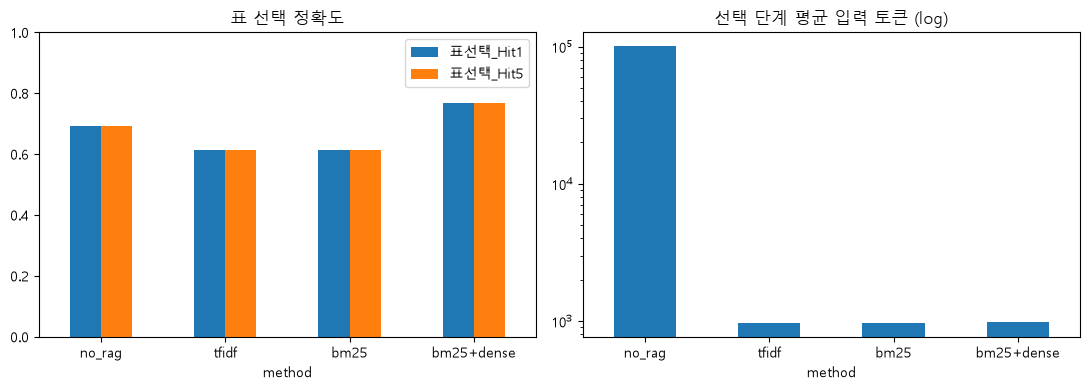

In [25]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
summary[["표선택_Hit1", "표선택_Hit5"]].plot.bar(ax=axes[0], rot=0, ylim=(0, 1), title="표 선택 정확도")
summary["선택단계_입력토큰"].plot.bar(ax=axes[1], rot=0, logy=True, title="선택 단계 평균 입력 토큰 (log)")
plt.tight_layout()
plt.show()

### 질문별 최종 답변 나란히 보기

In [26]:
for q, g in res_df.groupby("q", sort=False):
    print("=" * 100, f"\nQ. {q}   (gold: {', '.join(gold_map[q])})")
    for r in g.set_index("method").reindex(METHODS).itertuples():
        mark = "✓" if r.selected in gold_map[q] else "✗"
        print(f"\n--- [{r.Index}] {mark} {r.selected}  ({r.total_prompt_tokens:,} tokens, {r.total_sec}s)")
        print(r.answer if r.answer else f"(오류) {r.error}")

Q. 2023년 시군구 중 합계출산율이 가장 낮은 곳은 어디야?   (gold: DT_1B81A17, DT_1B81A23)

--- [no_rag] ✓ DT_1B81A23  (100,607 tokens, 77.29s)
nan

--- [tfidf] ✓ DT_1B81A23  (972 tokens, 1.52s)
nan

--- [bm25] ✓ DT_1B81A23  (954 tokens, 1.55s)
nan

--- [bm25+dense] ✓ DT_1B81A23  (970 tokens, 1.48s)
nan
Q. 2025년 전국 노령화지수와 중위연령 알려줘   (gold: DT_1IN2030)

--- [no_rag] ✓ DT_1IN2030  (103,673 tokens, 110.13s)
2025년 전국의 노령화 지수는 205.2이며, 중위 연령은 46.8세입니다.

출처: 주요 인구지표(부양비, 노령화지수, 중위연령 등) - 시군구(DT_1IN2030)

--- [tfidf] ✓ DT_1IN2030  (3,865 tokens, 1.23s)
2025년 전국의 노령화 지수는 205.2이며, 중위 연령은 46.8세입니다.

출처: 주요 인구지표(부양비, 노령화지수, 중위연령 등) - 시군구(DT_1IN2030)

--- [bm25] ✓ DT_1IN2030  (3,844 tokens, 1.88s)
2025년 전국의 노령화 지수는 205.2이며, 중위 연령은 46.8세입니다.

출처: 주요 인구지표(부양비, 노령화지수, 중위연령 등) - 시군구(DT_1IN2030)

--- [bm25+dense] ✓ DT_1IN2030  (3,950 tokens, 1.28s)
2025년 전국의 노령화 지수는 205.2이며, 중위 연령은 46.8세입니다.

출처: 주요 인구지표(부양비, 노령화지수, 중위연령 등) - 시군구(DT_1IN2030)
Q. 2050년 우리나라 총인구는 얼마로 전망돼?   (gold: DT_1BPA001, DT_1BPA401, DT_1BPA003)

--- [no_r

## 10. (선택) LLM-judge 답변 품질
정답 수치가 없으므로 "질문에 직접·구체적으로 답했는가"를 1~5점으로 채점합니다.
같은 모델이 채점하므로 참고 지표로만 쓰고, 핵심 지표는 9단계의 표 선택 정확도입니다.

In [27]:
JUDGE_SYS = """너는 통계 질의응답 평가자다. 질문과 답변을 보고 1~5점으로 채점한다.
5: 질문에 정확히 대응하는 수치(시점·단위 포함)로 직접 답함 / 3: 관련 있으나 일부만 답함 / 1: 답하지 못함 또는 엉뚱한 내용
JSON 한 개만 출력: {"score": 정수, "reason": "한 문장"}"""


def judge(q, a):
    if not a:
        return 1, "답변 없음"
    text, _ = chat([{"role": "system", "content": JUDGE_SYS},
                    {"role": "user", "content": f"[질문]\n{q}\n\n[답변]\n{a}"}], max_tokens=200)
    try:
        j = parse_json(text)
        return int(j["score"]), j.get("reason", "")
    except (ValueError, KeyError):
        return np.nan, text[:100]


res_df[["judge", "judge_reason"]] = [judge(r.q, r.answer) for r in res_df.itertuples()]
display(res_df.groupby("method", sort=False)["judge"].mean().reindex(METHODS).round(2))
res_df.to_csv(RESULTS / "compare_results.csv", index=False, encoding="utf-8-sig")

  429 rate limit → 29s 대기 후 재시도 (1/5)


method
no_rag        2.38
tfidf         2.17
bm25          2.15
bm25+dense    2.58
Name: judge, dtype: object